<a href="https://colab.research.google.com/github/srirammulukuntla11/AIEC/blob/main/aiec_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Real Mall Customers dataset loaded successfully!
Source: https://raw.githubusercontent.com/sharmaroshan/Clustering-of-Mall-Customers/master/Mall_Customers.csv

Number of customers: 200
Features: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

First five customers:
 CustomerID  Age  Annual Income (k$)  Spending Score (1-100)
          1   19                  15                      39
          2   21                  15                      81
          3   20                  16                       6
          4   23                  16                      77
          5   31                  17                      40

SOM CUSTOMER SEGMENTATION AND CLUSTER EXPLORATION SYSTEM
1. Customer Segmentation using SOM
2. Best Matching Unit Explorer
3. Dynamic Cluster Count Challenge
4. Customer Cluster Migration Analyzer
5. Cluster Prototype Generator
6. Outlier Customer Detector
7. SOM Cluster Quality Comparison
8. Exit
Enter your choice (1-8): 1
Enter number of SOM neurons: 2
En

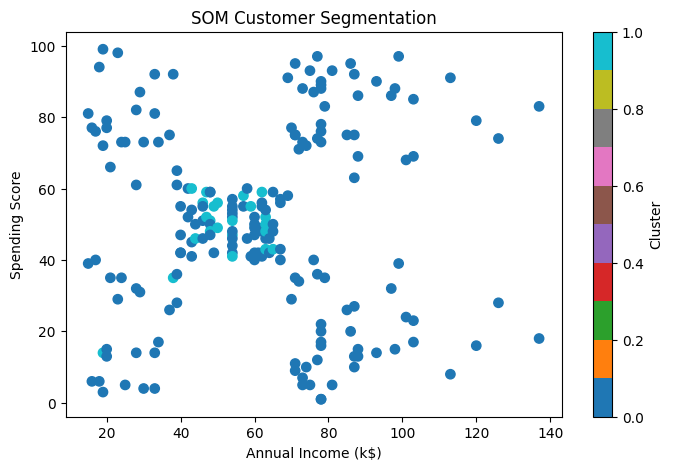


SOM CUSTOMER SEGMENTATION AND CLUSTER EXPLORATION SYSTEM
1. Customer Segmentation using SOM
2. Best Matching Unit Explorer
3. Dynamic Cluster Count Challenge
4. Customer Cluster Migration Analyzer
5. Cluster Prototype Generator
6. Outlier Customer Detector
7. SOM Cluster Quality Comparison
8. Exit
Enter your choice (1-8): 6

Top Five Most Unusual Customers:
 CustomerID  Age  Annual Income (k$)  Spending Score  Cluster  BMU Distance  Potential Outlier
          3   20                  16               6        2      0.617786               True
          7   35                  18               6        1      0.555699               True
          9   64                  19               3        3      0.534942               True
         15   37                  20              13        1      0.525129               True
         23   46                  25               5        3      0.491580               True

Outlier threshold: 0.44341
Potential outliers: 9

SOM CUSTOMER SEGME

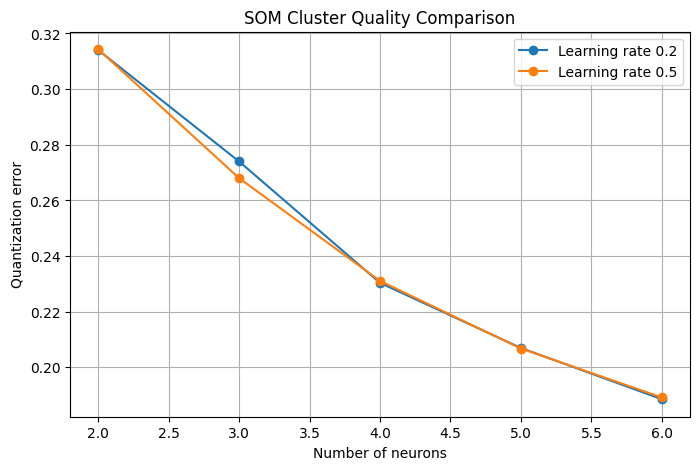


SOM CUSTOMER SEGMENTATION AND CLUSTER EXPLORATION SYSTEM
1. Customer Segmentation using SOM
2. Best Matching Unit Explorer
3. Dynamic Cluster Count Challenge
4. Customer Cluster Migration Analyzer
5. Cluster Prototype Generator
6. Outlier Customer Detector
7. SOM Cluster Quality Comparison
8. Exit
Enter your choice (1-8): 8
Thank you! Program terminated.


In [3]:
# ================================================================
# Exercise 8: Self-Organizing Map (SOM) Customer Segmentation
# Dataset: Mall Customers
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)

# ======================== DATASET LOADING ========================

def load_data():
    urls = [
        "https://raw.githubusercontent.com/sharmaroshan/Clustering-of-Mall-Customers/master/Mall_Customers.csv",
        "https://raw.githubusercontent.com/piyush-taneja/Mall-Customers/master/Mall_Customers.csv",
        "https://raw.githubusercontent.com/selva86/datasets/master/Mall_Customers.csv",
    ]

    data = None

    for url in urls:
        try:
            temp = pd.read_csv(url)
            temp.columns = [c.strip() for c in temp.columns]

            rename = {}
            for c in temp.columns:
                cl = c.lower().strip()
                if cl in ["customerid", "customer id"]:
                    rename[c] = "CustomerID"
                elif cl == "age":
                    rename[c] = "Age"
                elif "annual income" in cl:
                    rename[c] = "Annual Income (k$)"
                elif "spending score" in cl:
                    rename[c] = "Spending Score (1-100)"

            temp.rename(columns=rename, inplace=True)

            required = [
                "CustomerID", "Age",
                "Annual Income (k$)", "Spending Score (1-100)"
            ]

            if all(c in temp.columns for c in required):
                data = temp[required].dropna().copy()
                print("Real Mall Customers dataset loaded successfully!")
                print("Source:", url)
                break

        except Exception:
            continue

    if data is None:
        print("Dataset download failed.")
        print("Generating synthetic demonstration data so the program can run.")
        print("Note: These are simulated customers, not the original dataset.")

        n = 200
        data = pd.DataFrame({
            "CustomerID": np.arange(1, n + 1),
            "Age": np.random.randint(18, 71, n),
            "Annual Income (k$)": np.random.randint(15, 138, n),
            "Spending Score (1-100)": np.random.randint(1, 101, n)
        })

    data.reset_index(drop=True, inplace=True)
    return data


DATA = load_data()

FEATURES = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X_RAW = DATA[FEATURES].to_numpy(dtype=float)

scaler = MinMaxScaler()
X = scaler.fit_transform(X_RAW)

N = len(DATA)
print("\nNumber of customers:", N)
print("Features:", FEATURES)
print("\nFirst five customers:")
print(DATA.head().to_string(index=False))


# ======================== SOM IMPLEMENTATION ========================

class SOM:
    def __init__(self, neurons=4, learning_rate=0.3,
                 iterations=800, seed=42):
        self.neurons = neurons
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.seed = seed
        self.weights = None

    def fit(self, data):
        rng = np.random.default_rng(self.seed)
        indices = rng.choice(
            len(data),
            size=self.neurons,
            replace=(self.neurons > len(data))
        )
        self.weights = data[indices].copy()

        for step in range(self.iterations):
            progress = step / max(1, self.iterations - 1)
            lr = self.learning_rate * (1 - progress) + 0.01 * progress

            sample = data[rng.integers(0, len(data))]
            distances = np.linalg.norm(self.weights - sample, axis=1)
            bmu = np.argmin(distances)

            # Competitive learning: update the winning neuron.
            self.weights[bmu] += lr * (sample - self.weights[bmu])

        return self

    def distances(self, sample):
        return np.linalg.norm(self.weights - sample, axis=1)

    def predict_one(self, sample):
        distances = self.distances(sample)
        return int(np.argmin(distances)), distances

    def predict(self, data):
        return np.array([
            self.predict_one(row)[0] for row in data
        ])

    def quantization_error(self, data):
        labels = self.predict(data)
        distances = np.linalg.norm(
            data - self.weights[labels], axis=1
        )
        return float(np.mean(distances))


def train_som(neurons=4, lr=0.3, iterations=800, seed=42):
    model = SOM(neurons, lr, iterations, seed)
    model.fit(X)
    return model


def cluster_counts(model):
    labels = model.predict(X)
    counts = np.bincount(labels, minlength=model.neurons)
    return labels, counts


def show_clusters(model, labels):
    original_weights = scaler.inverse_transform(model.weights)

    for i in range(model.neurons):
        indices = np.where(labels == i)[0]
        print(f"\nCluster {i + 1}: {len(indices)} customers")

        if len(indices) == 0:
            print("No customers assigned.")
        else:
            print(DATA.iloc[indices].to_string(index=False))

    print("\nCluster Prototypes:")
    for i, w in enumerate(original_weights):
        print(
            f"Cluster {i + 1}: Age={w[0]:.1f}, "
            f"Income={w[1]:.1f}k, Spending Score={w[2]:.1f}"
        )

    plt.figure(figsize=(8, 5))
    plt.scatter(
        DATA["Annual Income (k$)"],
        DATA["Spending Score (1-100)"],
        c=labels, cmap="tab10", s=45
    )
    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score")
    plt.title("SOM Customer Segmentation")
    plt.colorbar(label="Cluster")
    plt.show()


def prototype_description(age, income, spending):
    age_desc = (
        "Young" if age < 30 else
        "Middle-Aged" if age < 45 else "Older"
    )
    income_desc = (
        "Low-Income" if income < 45 else
        "Moderate-Income" if income < 75 else "High-Income"
    )
    spending_desc = (
        "Low Spending" if spending < 40 else
        "Average Spending" if spending < 65 else "High Spending"
    )
    return f"{age_desc} {income_desc} Customers with {spending_desc}"


# ======================== MENU OPTION 1 ========================

def option1():
    neurons = int(input("Enter number of SOM neurons: "))
    lr = float(input("Enter learning rate (e.g. 0.3): "))
    iterations = int(input("Enter training iterations (e.g. 800): "))

    model = train_som(neurons, lr, iterations)
    labels, counts = cluster_counts(model)

    print("\nCluster distribution:")
    for i, count in enumerate(counts):
        print(f"Cluster {i + 1}: {count} customers")

    print("Quantization Error:", round(model.quantization_error(X), 5))
    show_clusters(model, labels)
    return model


# ======================== MENU OPTION 2 ========================

def option2():
    model = train_som(4, 0.3, 800)

    customer_id = int(input("Enter CustomerID: "))
    matches = np.where(DATA["CustomerID"].to_numpy() == customer_id)[0]

    if len(matches) == 0:
        print("Customer ID not found.")
        return

    idx = matches[0]
    bmu, distances = model.predict_one(X[idx])

    print("\nCustomer details:")
    print(DATA.iloc[idx].to_string())

    print("\nDistance from each neuron:")
    for i, d in enumerate(distances):
        print(f"Neuron {i + 1}: {d:.5f}")

    print("Best Matching Unit:", bmu + 1)
    print("Assigned Cluster:", bmu + 1)


# ======================== MENU OPTION 3 ========================

def option3():
    results = []

    for neurons in range(2, 7):
        model = train_som(neurons, 0.3, 800)
        labels, counts = cluster_counts(model)

        results.append({
            "Neurons": neurons,
            "Cluster Counts": counts.tolist(),
            "Empty Clusters": int(np.sum(counts == 0)),
            "Largest Cluster": int(counts.max()),
            "Smallest Cluster": int(counts.min()),
            "Quantization Error": model.quantization_error(X)
        })

    result_df = pd.DataFrame(results)
    print("\nDynamic Cluster Count Comparison:")
    print(result_df.to_string(index=False))

    valid = result_df[result_df["Empty Clusters"] == 0]
    if valid.empty:
        valid = result_df

    best = valid.sort_values("Quantization Error").iloc[0]
    print("\nSuggested neuron count:", int(best["Neurons"]))
    print("Reason: Lowest quantization error among eligible configurations.")


# ======================== MENU OPTION 4 ========================

def option4():
    model = train_som(4, 0.3, 800)

    customer_id = int(input("Enter CustomerID: "))
    matches = np.where(DATA["CustomerID"].to_numpy() == customer_id)[0]

    if len(matches) == 0:
        print("Customer not found.")
        return

    idx = matches[0]
    original = X_RAW[idx].copy()

    print("1. Change Annual Income")
    print("2. Change Spending Score")
    choice = input("Choose feature: ")

    feature_idx = 1 if choice == "1" else 2 if choice == "2" else None
    if feature_idx is None:
        print("Invalid choice.")
        return

    step = float(input("Enter step size (e.g. 2): "))
    direction = input("Direction (up/down): ").lower()

    if step <= 0 or direction not in ["up", "down"]:
        print("Invalid step or direction.")
        return

    initial_scaled = scaler.transform(original.reshape(1, -1))[0]
    initial_cluster, _ = model.predict_one(initial_scaled)

    print("Starting cluster:", initial_cluster + 1)
    migrated = False

    min_val = DATA[FEATURES[feature_idx]].min()
    max_val = DATA[FEATURES[feature_idx]].max()
    value = original[feature_idx]

    while True:
        value += step if direction == "up" else -step

        if value < min_val or value > max_val:
            break

        modified = original.copy()
        modified[feature_idx] = value
        scaled = scaler.transform(modified.reshape(1, -1))[0]
        bmu, distances = model.predict_one(scaled)

        print(
            f"{FEATURES[feature_idx]}={value:.2f}, "
            f"Cluster={bmu + 1}, Distance={distances[bmu]:.5f}"
        )

        if bmu != initial_cluster:
            print("Customer migrated to a different cluster at value:", value)
            migrated = True
            break

    if not migrated:
        print("No cluster migration observed in the tested direction.")


# ======================== MENU OPTION 5 ========================

def option5():
    model = train_som(4, 0.3, 800)
    labels, counts = cluster_counts(model)
    prototypes = scaler.inverse_transform(model.weights)

    print("\nCluster Prototype Descriptions:")
    for i, p in enumerate(prototypes):
        description = prototype_description(p[0], p[1], p[2])
        print(
            f"Cluster {i + 1} ({counts[i]} customers): {description}\n"
            f"  Age={p[0]:.1f}, Income={p[1]:.1f}k, Spending={p[2]:.1f}"
        )


# ======================== MENU OPTION 6 ========================

def option6():
    model = train_som(4, 0.3, 800)
    labels = model.predict(X)

    distances = np.linalg.norm(
        X - model.weights[labels], axis=1
    )
    threshold = distances.mean() + 2 * distances.std()

    rows = []
    for i, d in enumerate(distances):
        rows.append({
            "CustomerID": DATA.iloc[i]["CustomerID"],
            "Age": DATA.iloc[i]["Age"],
            "Annual Income (k$)": DATA.iloc[i]["Annual Income (k$)"],
            "Spending Score": DATA.iloc[i]["Spending Score (1-100)"],
            "Cluster": labels[i] + 1,
            "BMU Distance": d,
            "Potential Outlier": d >= threshold
        })

    results = pd.DataFrame(rows).sort_values(
        "BMU Distance", ascending=False
    )

    print("\nTop Five Most Unusual Customers:")
    print(results.head(5).to_string(index=False))

    print("\nOutlier threshold:", round(threshold, 5))
    print("Potential outliers:", int((distances >= threshold).sum()))


# ======================== MENU OPTION 7 ========================

def option7():
    rows = []

    for neurons in range(2, 7):
        for lr in [0.2, 0.5]:
            iterations = 800
            model = train_som(neurons, lr, iterations)
            labels, counts = cluster_counts(model)

            rows.append({
                "Neurons": neurons,
                "Learning Rate": lr,
                "Iterations": iterations,
                "Empty Clusters": int(np.sum(counts == 0)),
                "Quantization Error": model.quantization_error(X),
                "Largest Cluster": int(counts.max()),
                "Smallest Cluster": int(counts.min())
            })

    report = pd.DataFrame(rows).sort_values("Quantization Error")
    print("\nSOM Cluster Quality Comparison:")
    print(report.to_string(index=False))

    best = report.iloc[0]
    print(
        f"\nBest configuration: {int(best['Neurons'])} neurons, "
        f"learning rate {best['Learning Rate']}, "
        f"quantization error {best['Quantization Error']:.5f}"
    )

    plt.figure(figsize=(8, 5))
    for lr in [0.2, 0.5]:
        subset = report[report["Learning Rate"] == lr].sort_values("Neurons")
        plt.plot(
            subset["Neurons"],
            subset["Quantization Error"],
            marker="o",
            label=f"Learning rate {lr}"
        )

    plt.xlabel("Number of neurons")
    plt.ylabel("Quantization error")
    plt.title("SOM Cluster Quality Comparison")
    plt.legend()
    plt.grid(True)
    plt.show()


# ======================== MAIN MENU ========================

def main():
    while True:
        print("\n" + "=" * 65)
        print("SOM CUSTOMER SEGMENTATION AND CLUSTER EXPLORATION SYSTEM")
        print("=" * 65)
        print("1. Customer Segmentation using SOM")
        print("2. Best Matching Unit Explorer")
        print("3. Dynamic Cluster Count Challenge")
        print("4. Customer Cluster Migration Analyzer")
        print("5. Cluster Prototype Generator")
        print("6. Outlier Customer Detector")
        print("7. SOM Cluster Quality Comparison")
        print("8. Exit")

        choice = input("Enter your choice (1-8): ").strip()

        try:
            if choice == "1":
                option1()
            elif choice == "2":
                option2()
            elif choice == "3":
                option3()
            elif choice == "4":
                option4()
            elif choice == "5":
                option5()
            elif choice == "6":
                option6()
            elif choice == "7":
                option7()
            elif choice == "8":
                print("Thank you! Program terminated.")
                break
            else:
                print("Please enter a valid choice from 1 to 8.")

        except Exception as e:
            print("Error:", e)
            print("Please check your input and try again.")


main()